In [1]:
import numpy as np
import agama
agama.setUnits(length=1, velocity=1, mass=1) 
import matplotlib.pyplot as plt
import sys
sys.path.append('/suphys/aani0116/Work/neutronstar_minicluster/my_modules')
import numpy as np
from scipy.stats import uniform_direction
from mc_declare import *
from scipy.interpolate import interp1d
pot_mw = agama.Potential('/suphys/aani0116/minicluster/minicluster_tidal/Agama/data/McMillan17.ini')
from mass_loss_bradkav import mass_loss_frac
from reverse_orbit import reverse_orbit,reverse_orbit_multiple
from mass_loss_new import *
from N_calculator import N_encounter 
from N_calculator import stellar_rho_total
from hmf import *
from mc_xv import generate_xv_at,generate_xv
from scipy.integrate import quad
from scipy.interpolate import interp1d


In [2]:
def dndm(M):
    return (M**-1.8)*(np.exp(-M/1e-6))*(np.exp(-1e-13/M))
def dndlogm(pow):
    M=10**pow
    return (M**-0.8)*(np.exp(-M/1e-6))*(np.exp(-1e-13/M))


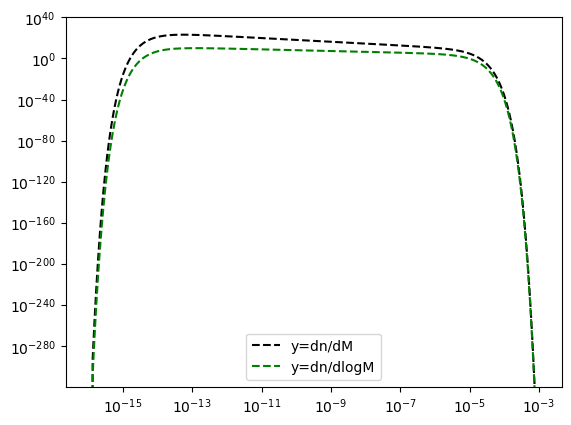

In [3]:
m=np.logspace(-16,-3,1000)
dn_dm=dndm(m)
plt.loglog(m,dndm(m),'k--',label='y=dn/dM')
logm=np.linspace(-16,-3,1000)
plt.plot(10**logm,dndlogm(logm),'g--',label='y=dn/dlogM')
plt.legend()

In [4]:
def get_halo_weighted(N):
    get_n_vec=np.vectorize(lambda a, b: quad(dndlogm,  b,a)[0])
    upper_m,lower_m=logm[1:],logm[:-1]
    logm_mid=(upper_m+lower_m)/2
    n=get_n_vec(upper_m,lower_m)
    M_total=(10**logm_mid)*n
    prob=M_total/M_total.sum()
    prob_extrapolate = interp1d(logm_mid, prob, kind='linear', fill_value='extrapolate')
    #generate dummy array from which we draw
    m_dummy=np.linspace(-18,-1,10000000)
    p=prob_extrapolate(m_dummy)/prob_extrapolate(m_dummy).sum()
    mc_mass=10**np.random.choice(m_dummy,N,p=p)
    return mc_mass

In [5]:
def get_halo(N):
    get_n_vec=np.vectorize(lambda a, b: quad(dndlogm,  b,a)[0])
    upper_m,lower_m=logm[1:],logm[:-1]
    logm_mid=(upper_m+lower_m)/2
    n=get_n_vec(upper_m,lower_m)
    
    prob=n/n.sum()
    prob_extrapolate = interp1d(logm_mid, prob, kind='linear', fill_value='extrapolate')
    #generate dummy array from which we draw
    m_dummy=np.linspace(-18,-1,100000)
    p=prob_extrapolate(m_dummy)/prob_extrapolate(m_dummy).sum()
    mc_mass=10**np.random.choice(m_dummy,N,p=p)
    return mc_mass

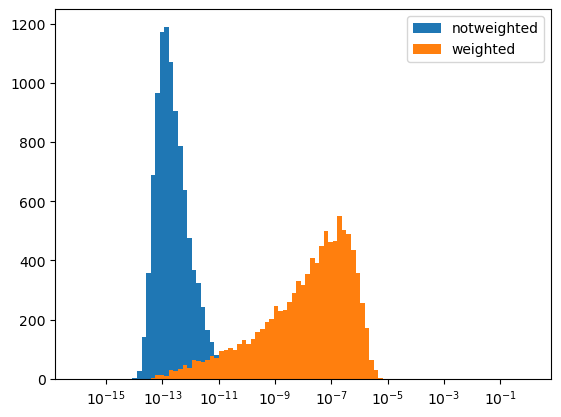

In [6]:
plt.hist(get_halo(10000),bins=np.logspace(-16,0,100),alpha=1,label='notweighted')
plt.hist(get_halo_weighted(10000),bins=np.logspace(-16,0,100),alpha=1,label='weighted')
#plt.loglog(m,dndm(m),'k--',label='y=dn/dM')
plt.xscale('log')
#plt.yscale('log')
plt.legend()

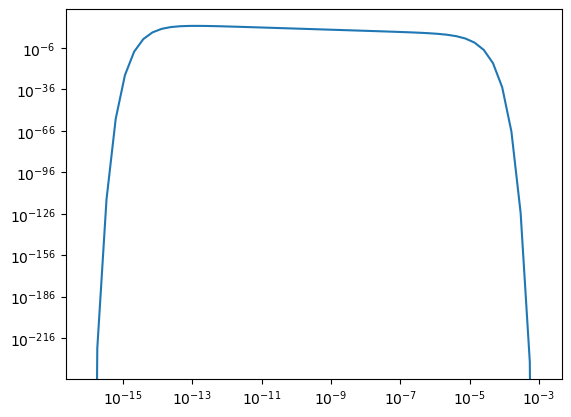

In [22]:
f=lambda M:(M**-0.8)*(np.exp(-M/1e-6))*(np.exp(-1e-13/M))
plt.loglog(np.logspace(-16,-3),f(np.logspace(-16,-3)))

In [ ]:
get_mbin_vec=np.vectorize(lambda a, b: quad(f,  b,a)[0])
m=np.logspace(-15,-5,10000)
mbin=get_mbin_vec(m[1:],m[:-1])

In [35]:
m_mid=m[1:]-m[:-1]

In [24]:
mbin_norm=mbin/mbin.sum()

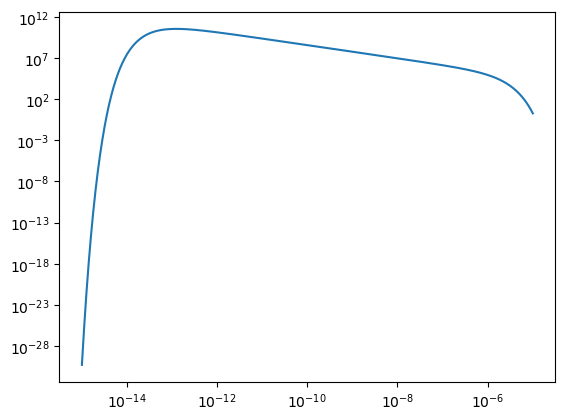

In [ ]:
plt.plot(m[1:],mbin_norm/m_mid)
plt.xscale('log')


In [38]:
mbin_norm


array([1.20746755e-47, 1.14341298e-46, 1.02897504e-45, 8.81012641e-45,
       7.18497317e-44, 5.58744051e-43, 4.14775997e-42, 2.94228579e-41,
       1.99652089e-40, 1.29723227e-39, 8.07874174e-39, 4.82691170e-38,
       2.76950870e-37, 1.52736464e-36, 8.10362234e-36, 4.13993138e-35,
       2.03824781e-34, 9.67909385e-34, 4.43692447e-33, 1.96492821e-32,
       8.41334098e-32, 3.48561639e-31, 1.39831371e-30, 5.43576728e-30,
       2.04907766e-29, 7.49549635e-29, 2.66245961e-28, 9.18958380e-28,
       3.08405292e-27, 1.00701872e-26, 3.20120382e-26, 9.91318863e-26,
       2.99223636e-25, 8.80872961e-25, 2.53053404e-24, 7.09796227e-24,
       1.94497225e-23, 5.20932722e-23, 1.36446828e-22, 3.49686445e-22,
       8.77289022e-22, 2.15558551e-21, 5.18981461e-21, 1.22490715e-20,
       2.83540691e-20, 6.43991648e-20, 1.43577064e-19, 3.14349678e-19,
       6.76150021e-19, 1.42938799e-18, 2.97101715e-18, 6.07400630e-18,
       1.22186622e-17, 2.41941297e-17, 4.71726470e-17, 9.05976261e-17,
      

In [39]:
m_mid

array([2.33165783e-17, 2.38602412e-17, 2.44165803e-17, 2.49858914e-17,
       2.55684769e-17, 2.61646463e-17, 2.67747164e-17, 2.73990111e-17,
       2.80378623e-17, 2.86916093e-17, 2.93605995e-17, 3.00451882e-17,
       3.07457392e-17, 3.14626246e-17, 3.21962254e-17, 3.29469312e-17,
       3.37151409e-17, 3.45012626e-17, 3.53057140e-17, 3.61289225e-17,
       3.69713253e-17, 3.78333701e-17, 3.87155148e-17, 3.96182282e-17,
       4.05419897e-17, 4.14872902e-17, 4.24546318e-17, 4.34445286e-17,
       4.44575063e-17, 4.54941033e-17, 4.65548701e-17, 4.76403704e-17,
       4.87511808e-17, 4.98878915e-17, 5.10511064e-17, 5.22414436e-17,
       5.34595353e-17, 5.47060287e-17, 5.59815861e-17, 5.72868852e-17,
       5.86226193e-17, 5.99894982e-17, 6.13882480e-17, 6.28196119e-17,
       6.42843503e-17, 6.57832414e-17, 6.73170815e-17, 6.88866855e-17,
       7.04928873e-17, 7.21365403e-17, 7.38185175e-17, 7.55397128e-17,
       7.73010404e-17, 7.91034362e-17, 8.09478577e-17, 8.28352847e-17,
      